# Is the unchanged decomposition already poor at the cipher's cue? (E48)

## The answer

Yes. We rebuilt the unchanged model from the subcomponents its causal-importance function marks important. At the cue of the word ciphers, that model is about twice as far from the original as it is on ordinary text, over the agreed line on both random ciphers. So the planned new part of the pass would have judged the decomposition, not the map. The pass for new behaviours stays the adversarial check on ordinary text, with the cue reading printed beside it.

## What we were trying to test

E42 found that teacher training copies a word-cipher fine-tune into the decomposition and passes the adversarial check on ordinary text. Yet the model rebuilt from the subcomponents Γ marks important at the cipher's cue keeps almost none of a random cipher. On 2026-10-29 the user chose to add a new part to the pass: the behaviour must also be kept by the parts Γ switches on, on the task's own text. The same decision said to check the unchanged decomposition first. If its own masked model is already poor at the cipher's cue, the new reading would fail every map for a reason that lies in the decomposition, and the pass falls back to the ordinary-text check.

This run made only that first check. The state is W₀, the unchanged model with its decomposition. Its **masked model** is the forward pass with every subcomponent multiplied by Γ's causal-importance value $g$, with Γ reading W₀'s own activations. Δ, the part of the weights outside the subcomponents, is held at W₀'s value. Three quantities:

- **The KL at the cue**: the mean over a task's held-out windows of $\mathrm{KL}(W_0 \,\|\, \text{masked } W_0)$ at the one position after the cipher's marker and key, in nats. 0 means the masked model reproduces W₀ there exactly.
- **The KL on ordinary text**: the same, per position, averaged over 256 rows of Pile validation text.
- **The ratio $F$** of the two. $F = 1$ means the masked model is as close to W₀ at the cue as on ordinary text.

The stop rule reads $F$ on the two random ciphers, one with 32 key-to-word pairs and one with a single pair. At 1.5 or over on either, the new reading is not used. Printed beside, and not scored, are two kinds of reference. One is the identity control, where each of the same 32 keys maps to itself. The others are the cue windows of four earlier tasks that VPD is not suspected of losing: emoticon → o, the first two rungs of the task ladder, and the rare target " in" → " Fig". Two apparatus checks came first: the masked forward reproduces the harness's ordinary-text reading, and W₀'s Δ really enters it.

## What we expected, and why

We leaned towards the fallback, with medium-low confidence. With Δ left out, earlier numbers put the masked model 0.69 nats from W₀ at the cipher's cue, against 0.35 on ordinary text, a ratio of about 2. Putting W₀'s Δ back in could have lowered either number by an amount nobody had measured, so the lean was not firm.

## What we observed

### Is the unchanged decomposition's masked model already poor at the cipher's cue? Yes, on both random ciphers

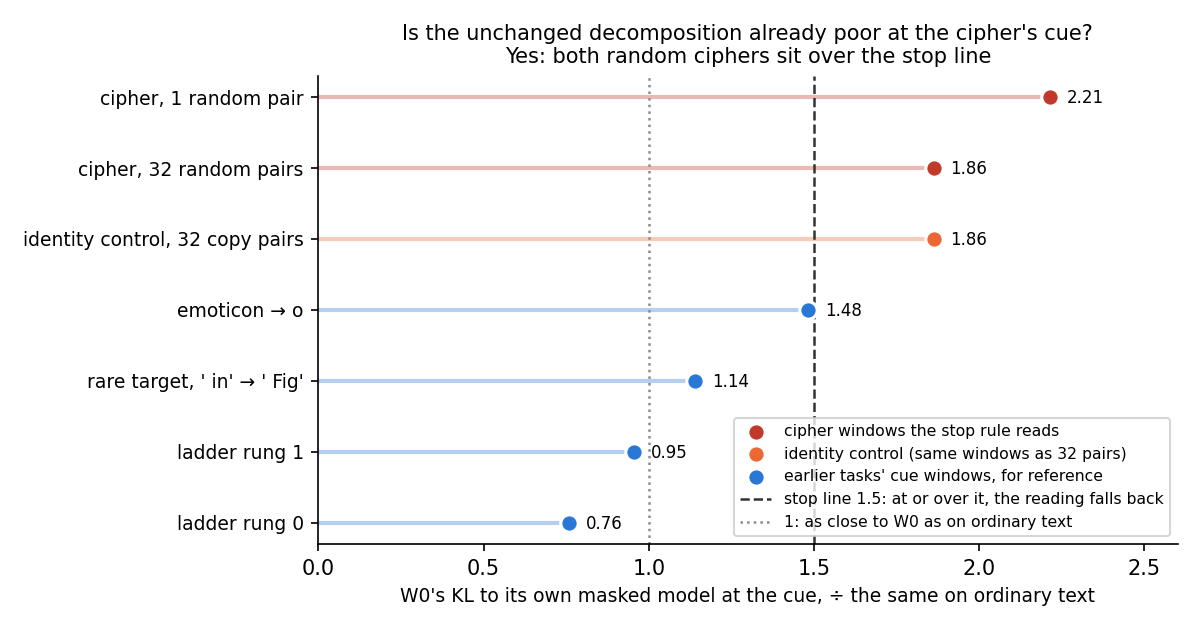

In [1]:
# The figure, made by experiments/pass_reread/plot.py from results/saved.json (no model).
from IPython.display import Image

Image("../experiments/pass_reread/figures/e48_s1_fidelity.png")

**Reading it.** Yes. At the cue of the 32-pair cipher the masked model is 0.65 nats from W₀, 1.86 times its distance on ordinary text. On the one-pair cipher it is 0.77 nats, 2.21 times. Both dots sit right of the dashed stop line at 1.5, so the run stopped after this check, as planned. The four earlier tasks' cues read 0.76 to 1.48, all under the line, with emoticon closest to it. So the cipher's cue context is harder for the decomposition than the cues of the tasks it handles, and harder than the line allows.

The identity control reads exactly what the 32-pair cipher reads. That is expected: both tasks use the same windows, drawn once for the same 32 keys, and only the word each key maps to differs. This reading compares W₀ with its own masked model, so it never looks at the target word. The one-pair cipher has its own windows and reads differently. Putting W₀'s Δ into the masked forward changed every reading by under 0.004 nats, so the choice of Δ convention did not matter here.

In [2]:
# The numbers behind the figure, from the results file (no model).
import json
from pathlib import Path

s1 = json.loads(Path("../experiments/pass_reread/results/saved.json").read_text())["S1"]
names = {"rand1": "cipher, 1 pair", "rand32": "cipher, 32 pairs", "ident32": "identity, 32 pairs",
         "emoticon": "emoticon", "r2_t275_v2667": "rare target", "r1_t534_v369": "ladder rung 1",
         "r0_t352_v310": "ladder rung 0"}
print(f"{'cue windows':20s} {'KL at cue':>10s} {'ratio F':>8s} {'over 1.5':>9s}")
for key, name in names.items():
    print(f"{name:20s} {s1['K0'][key]['K']:10.3f} {s1['F'][key]:8.2f} {str(s1['F'][key] >= 1.5):>9s}")
print(f"{'ordinary text':20s} {s1['pile']['K']:10.3f} {1:8.2f}")
print("decision:", s1["decision"])

cue windows           KL at cue  ratio F  over 1.5
cipher, 1 pair            0.771     2.21      True
cipher, 32 pairs          0.648     1.86      True
identity, 32 pairs        0.648     1.86      True
emoticon                  0.516     1.48     False
rare target               0.397     1.14     False
ladder rung 1             0.332     0.95     False
ladder rung 0             0.264     0.76     False
ordinary text             0.348     1.00
decision: fallback


## What we learned

Before any update, the unchanged decomposition is about twice as far from W₀ at the cipher's cue as on ordinary text. The cue follows a marker the model never sees in ordinary text, a context the decomposition was not trained on. A reading of behaviour kept by the parts Γ switches on at that cue would measure the decomposition's own gap as much as the map's. For the weak version in `GOALS.md`, the pass on new behaviours therefore stays the adversarial check on ordinary text, and the cue reading is printed beside each verdict without deciding it. E42's result stands as filed: teacher training passes on all three ciphers, while the model rebuilt from the subcomponents Γ marks important at the cue keeps almost none of a random cipher.

Two cards follow. The E42 criterion is decided as the fallback the user named: the ordinary-text check decides, with the cue reading beside it. The rare target was to be re-read under the new reading; since that reading is not used, its outcome under the ordinary-text check stands, "not placed, narrow miss", with no rerun.

## How compelling is the evidence

Each cipher reading is a mean over 97 held-out windows, on one decomposition and one card. The reading has no randomness: Γ's values and the masked forward are deterministic, so a rerun on the same card reads the same. Both ciphers clear the line, by 0.36 and 0.71. The line is the project's fixed 1.5, applied here to W₀ against itself and filed before the run; the verdict rests on that choice. Any line from 1.49 to 2.21 would keep every earlier task under it and still give the fallback. The reading compares one cue position with the mean over every ordinary-text position. The earlier tasks' cues are the same kind of position and read lower, so the cipher's excess is not only the position type. In absolute terms the gap is small beside the 10 to 13 nats that E42's fine-tunes move the cue. But a share measured against a reference twice as poor as usual would not have read the map alone.

## Surprises

None reversed a prediction: the run landed on its lean. One small surprise: W₀'s Δ adds almost nothing under the masks, under 0.004 nats at any cue, though with every mask at 1 leaving it out costs 0.011 nats per ordinary-text position.

## What next

1. Nothing runs on this line by default. Under the fallback, the E42 copies' cue readings are already in E42's write-up. The E34 copies' cue readings are printed nowhere yet; a free, ten-minute rerun of the copy-reading stage, reported beside and deciding nothing, would print them if wanted.
2. If a later decomposition or a masked training brings W₀ under 1.5 at the cipher's cue, the new reading becomes usable, and this run's code reads every saved copy unchanged. The Qwen line's plan uses the same share; its own W₀ should be read the same way at its task's cue first.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| S1 A1 | masked forward is the harness's | Δ-out Pile KL within 2% of 0.348 | 0.3482 | pass |
| S1 A2 | Δ enters the masked forward | fp32 KL at mask 1 ≤ 1e-4 | −1.3e-9 | pass |
| S1 | W₀ already poor at the cue; lean fallback | F ≥ 1.5 on rand32 or rand1 | 1.86, 2.21 | **fallback**, as leaned |
| P1-P5 | copies and controls under the new reading | share ≥ 0.8 | not read | not scored: stopped by design |
| P6 | batch-order spread under 0.05 | max share difference | not read | not scored |
| P7 | carriers of the E42 gain: tens | n50 count | not read | not scored |

## Not run

- The saved copies under the new reading: E42's six, the r1 and r2 SGD copies including the rare target's, the six LoRA copies, and the do-nothing states. Stopped by design.
- The subcomponents that carry the E42 gain. Stopped by design.
- The second job, E34's six copies regenerated on the L40. Not submitted, by the plan.
- The "reported beside" rerun of the copies' cue readings. Not asked for.

## Provenance

Slurm job 42757, MATS cluster debug QoS, NVIDIA L40, about 2 minutes, exit 0, $0. Results `experiments/pass_reread/results/saved.json`; predictions `experiments/pass_reread/results/predictions.json`, filed before the run; plan `reports/plans/2026-10-29_plan_e48-pass-reread.md`; full tables in `reports/analyses/2026-10-29_analysis_e48-pass-reread.md`.